# Phase 6 — Run and validate the Ecuador 2022 network

This notebook is the student-facing full-year workflow. It performs artifact preflight, loads the Phase 5 candidate, solves all 8,760 hourly snapshots with HiGHS, calculates the annual energy mix and energy-balance diagnostics, and writes the validation tables, JSON summary, report input, and figures. The solve is intentionally manual because it is a scientific run, not a CI test.

## Reproducibility contract

Run this notebook from the repository root in the approved `pypsa-earth-ec` environment. Do not substitute a different weather year, reference table, solver, or network. If preflight fails, stop before scientific processing. The criteria are documented in `docs/PHASE_06_VALIDATION_CRITERIA.md`; configured thresholds are exploratory engineering screens, not calibration targets.

In [1]:
from pathlib import Path
import hashlib, json
import matplotlib.pyplot as plt
import pandas as pd
import pypsa

ROOT = Path.cwd()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'config/artifacts.yaml').is_file(), 'Run from the repository or a child directory'
import sys
sys.path.insert(0, str(ROOT))
from src.artifacts import run_preflight, format_preflight_report
from src.validation import (load_validation_contract, load_raw_supply_reference,
    build_supply_reference, calculate_validation_metrics, screen_validation,
    validate_annual_coverage, enforce_historical_import_energy)
from src.phase06d import candidate_name, write_candidate_manifest

preflight = run_preflight('06_validation')
print(format_preflight_report(preflight))
preflight.raise_for_errors()

Cannot find header.dxf (GDAL_DATA is not defined)


Artifact preflight: PASS (stage=06_validation)
  valid        pypsa_earth_base_ec: cached file verified
  valid        renewable_profile_solar_ec: cached file verified
  valid        gadm_ecuador_41: cached file verified
  valid        renewable_profile_onwind_ec: cached file verified
  valid        demand_template_2013_ec: cached file verified
  valid        cenace_sni_2022_monthly_demand: cached file verified
  valid        cenace_2022_net_supply: cached file verified
  valid        generation_existing_2022_source: cached file verified
  valid        generation_location_evidence_2022: cached file verified
  valid        generation_location_overrides_2022: cached file verified
  valid        cenace_2022_commissioning_events: cached file verified
  valid        generation_fleet_2022_normalized: cached file verified
  valid        generation_monthly_flows: cached file verified
  valid        hydro_profile_assignments_2022: cached file verified
  valid        topology_repairs_2022: cache

## Load and solve the complete annual candidate

The candidate is the regenerated Phase 5 product containing the reviewed La Concordia-Pedernales and Minas-San Ildefonso topology repairs, documented Colombia interfaces, and separate Colombia/Peru export sinks. Historical mode constrains annual imports to 465.83 GWh within the configured 5% input band; future scenarios must disable that historical energy constraint. The solver status and termination condition are retained in the run metadata.

In [2]:
candidate_path = ROOT / 'data/processed/networks/network_base_filled.nc'
candidate = candidate_name()
result_dir = ROOT / 'results/phase_06d' / candidate
figure_dir = ROOT / 'reports/figures/phase_06'
result_dir.mkdir(parents=True, exist_ok=True); figure_dir.mkdir(parents=True, exist_ok=True)
network = pypsa.Network(candidate_path)
contract = load_validation_contract(ROOT / 'config/validation_2022.yaml')
comparable, reasons = validate_annual_coverage(network.snapshots, 2022)
assert comparable, reasons
reasons.append('CENACE production and demand totals retain an unresolved 931.43 GWh metering-boundary residual; total-energy screening is disabled and the run remains PARTIAL.')
solver_status, termination = network.optimize(
    solver_name='highs',
    extra_functionality=lambda n, snapshots: enforce_historical_import_energy(n, snapshots, contract),
)
print({'solver_status': str(solver_status), 'termination_condition': str(termination)})
solved_path = result_dir / 'network_solved_2022.nc'
network.export_to_netcdf(solved_path)

C:\Users\fpenaherrera_vaca\.conda\envs\pypsa-earth-ec\Lib\site-packages\xarray\backends\plugins.py:110: RuntimeWarning:

Engine 'cfgrib' loading failed:
Cannot find the ecCodes library



INFO:pypsa.io:Imported network network_base_filled.nc has buses, carriers, generators, lines, links, loads, transformers


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io:Writing objective.


Writing constraints.:   0%|          | 0/13 [00:00<?, ?it/s]

...

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 3337560 primals, 7875242 duals
Objective: 1.85e+09
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper, Transformer-fix-s-lower, Transformer-fix-s-upper, Link-fix-p-lower, Link-fix-p-upper, Kirchhoff-Voltage-Law were not assigned to the network.


{'solver_status': 'ok', 'termination_condition': 'optimal'}


INFO:pypsa.io:Exported network 'network_solved_2022.nc' contains: buses, generators, links, transformers, loads, lines, carriers


<xarray.Dataset> Size: 93MB
Dimensions:                       (snapshots: 8760, investment_periods: 0,
                                   buses_i: 111, buses_t_p_i: 101,
                                   buses_t_v_ang_i: 110,
                                   buses_t_marginal_price_i: 111,
                                   generators_i: 245,
                                   generators_t_p_max_pu_i: 94,
                                   ...
                                   links_t_p0_i: 2, links_t_p1_i: 2,
                                   transformers_i: 19, transformers_t_p0_i: 18,
                                   transformers_t_p1_i: 18, loads_i: 253,
                                   loads_t_p_set_i: 253, loads_t_p_i: 253,
                                   lines_i: 115, lines_t_p0_i: 115,
                                   lines_t_p1_i: 115, carriers_i: 11)
Coordinates: (12/22)
  * snapshots                     (snapshots) int64 70kB 0 1 2 ... 8758 8759
  * investment_periods            (investment_periods) int64 0B 
  * buses_i                       (buses_i) object 888B '1' ... 'interconnect...
  * buses_t_p_i                   (buses_t_p_i) object 808B '1' ... 'intercon...
  * buses_t_v_ang_i               (buses_t_v_ang_i) object 880B '1' ... '294'
  * buses_t_marginal_price_i      (buses_t_marginal_price_i) object 888B '1' ...
    ...                            ...
  * loads_t_p_set_i               (loads_t_p_set_i) object 2kB 'load_0' ... '...
  * loads_t_p_i                   (loads_t_p_i) object 2kB 'load_0' ... 'expo...
  * lines_i                       (lines_i) object 920B '0' ... 'repair_line_...
  * lines_t_p0_i                  (lines_t_p0_i) object 920B '0' ... 'repair_...
  * lines_t_p1_i                  (lines_t_p1_i) object 920B '0' ... 'repair_...
  * carriers_i                    (carriers_i) object 88B 'AC' ... 'solar'
Data variables: (12/83)
    snapshots_snapshot            (snapshots) datetime64[ns] 70kB 2022-01-01 ...
    snapshots_objective           (snapshots) float64 70kB 1.0 1.0 ... 1.0 1.0
    snapshots_generators          (snapshots) float64 70kB 1.0 1.0 ... 1.0 1.0
    snapshots_stores              (snapshots) float64 70kB 1.0 1.0 ... 1.0 1.0
    investment_periods_objective  (investment_periods) float64 0B 
    investment_periods_years      (investment_periods) float64 0B 
    ...                            ...
    lines_s_nom_opt               (lines_i) float64 920B 1.028e+03 ... 230.0
    lines_t_p0                    (snapshots, lines_t_p0_i) float64 8MB -126....
    lines_t_p1                    (snapshots, lines_t_p1_i) float64 8MB 126.6...
    carriers_co2_emissions        (carriers_i) float64 88B 0.0 0.0 ... 0.0 0.0
    carriers_color                (carriers_i) object 88B '#888888' ... '#f9d...
    carriers_nice_name            (carriers_i) object 88B 'Alternating curren...
Attributes:
    network__linearized_uc:      0
    network__multi_invest:       0
    network_name:                PyPSA-Earth
    network_objective:           1849288852.5641506
    network_objective_constant:  0
    network_pypsa_version:       0.30.3
    network_srid:                4326
    crs:                         {"_crs": "GEOGCRS[\"WGS 84\",ENSEMBLE[\"Worl...
    meta:                        {"project": "EcuadorElectricGrid", "model_ye...

## Annual supply and validation metrics

Positive generator dispatch is aggregated through the configured carrier mapping. Load shedding is reported separately and never counted as actual supply.

In [3]:
raw = load_raw_supply_reference(ROOT / contract['supply_reference']['raw_table'])
reference = build_supply_reference(raw, contract)
dispatch = network.generators_t.p.clip(lower=0)
weighted_gwh = dispatch.mul(network.snapshot_weightings.generators, axis=0).sum() / 1000
by_carrier = weighted_gwh.groupby(network.generators.loc[weighted_gwh.index, 'carrier']).sum()
load_shedding_gwh = float(by_carrier.get('load_shedding', 0.0))
by_carrier = by_carrier.drop(labels=['load_shedding'], errors='ignore')
domestic_ids = network.loads.index[network.loads.carrier.eq('electricity')]
export_ids = network.loads.index[network.loads.carrier.eq('export')]
domestic_demand_gwh = float(network.loads_t.p_set.loc[:, domestic_ids].mul(network.snapshot_weightings.objective, axis=0).sum().sum() / 1000)
exports_gwh = float(network.loads_t.p_set.loc[:, export_ids].mul(network.snapshot_weightings.objective, axis=0).sum().sum() / 1000)
energy_balance_residual_gwh = float(by_carrier.sum() + load_shedding_gwh - domestic_demand_gwh - exports_gwh)
from src.validation import aggregate_model_supply
simulated = aggregate_model_supply(by_carrier, contract)
rows, metrics = calculate_validation_metrics(simulated, reference)
screen = screen_validation(metrics, rows, contract['acceptance'])
validation_csv = result_dir / 'validation_2022.csv'; rows.to_csv(validation_csv, index=False)
summary = {'status': 'FAIL' if not screen['passed'] else 'PARTIAL', 'metrics': metrics, 'screening': screen,
           'comparability': {'status': 'PARTIAL', 'reasons': reasons},
           'load_shedding_gwh': load_shedding_gwh,
           'domestic_demand_gwh': domestic_demand_gwh, 'exports_gwh': exports_gwh,
           'energy_balance_residual_gwh': energy_balance_residual_gwh,
           'unresolved_accounting_residual': contract['accounting_residual'],
           'solver_status': str(solver_status),
           'termination_condition': str(termination), 'reference_source': contract['sources']['CENACE_ANNUAL_2022']}
(result_dir / 'validation_summary.json').write_text(json.dumps(summary, indent=2, default=str), encoding='utf-8')
display(rows); print(json.dumps(summary, indent=2, default=str))

,carrier,reference_gwh,simulated_gwh,reference_share,simulated_share,signed_error_gwh,absolute_error_gwh,signed_error_pp,absolute_error_pp,relative_error,absolute_relative_error
0,hydro,24499.54,22756.118463,0.854101,0.819946,-1743.421537,1743.421537,-3.415423,3.415423,-0.071161,0.071161
1,thermal,3393.35,4349.358663,0.118299,0.156716,956.008663,956.008663,3.841705,3.841705,0.281730,0.281730
2,nonconventional,325.89,158.583554,0.011361,0.005714,-167.306446,167.306446,-0.564708,0.564708,-0.513383,0.513383
3,interconnection,465.83,489.121500,0.016240,0.017624,23.291500,23.291500,0.138426,0.138426,0.050000,0.050000


{
  "status": "FAIL",
  "metrics": {
    "reference_total_gwh": 28684.61,
    "simulated_total_gwh": 27753.1821807384,
    "total_energy_relative_error": 0.03247134331830205,
    "tvd": 0.039801306919787185
  },
  "screening": {
    "checks": {
      "max_tvd": false,
      "max_hydro_error_pp": false,
      "max_thermal_error_pp": false,
      "max_nonconventional_error_pp": false,
      "max_interconnection_error_pp": true
    },
    "passed": false,
    "status": "FAIL"
  },
  "comparability": {
    "status": "PARTIAL",
    "reasons": [
      "CENACE production and demand totals retain an unresolved 931.43 GWh metering-boundary residual; total-energy screening is disabled and the run remains PARTIAL."
    ]
  },
  "load_shedding_gwh": 0.007819261851312945,
  "domestic_demand_gwh": 27561.62,
  "exports_gwh": 191.57000000000002,
  "energy_balance_residual_gwh": 2.5434587769268546e-10,
  "unresolved_accounting_residual": {
    "gwh": 931.43,
    "treatment": "report_only_not_modeled",


## Figures and handoff

The three figures are saved for the Phase 6 report. Review energy balance residuals, exports, storage flows, curtailment, and load shedding before treating the result as scientifically accepted.

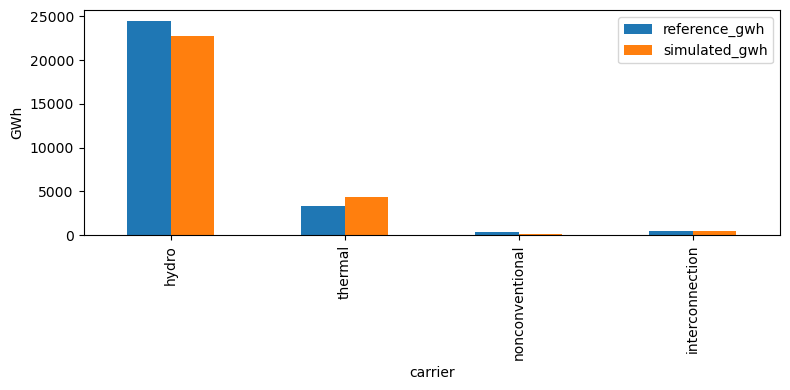

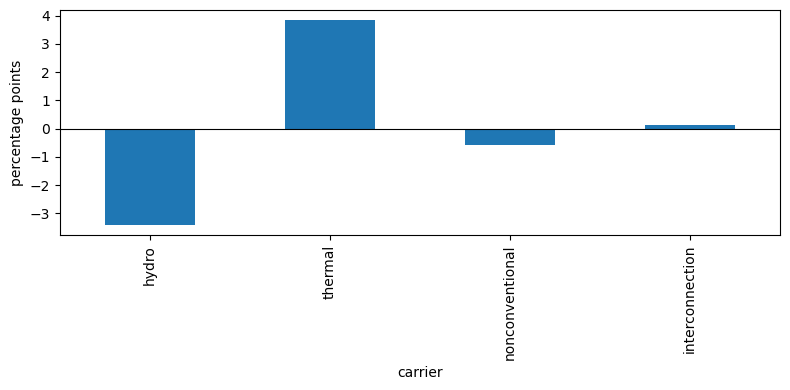

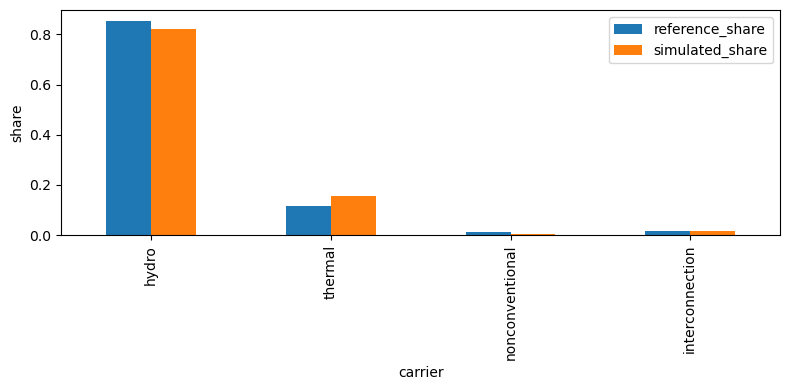

{'network': 'results\\phase_06d\\baseline\\network_solved_2022.nc', 'sha256': 'c9be579b85cd5d544836e1d58efa58181c5999d6e25108d6a5f89132799a6359', 'validation_csv': 'results\\phase_06d\\baseline\\validation_2022.csv', 'status': 'manual Phase 6 run output'}


WindowsPath('C:/Repositories/Repos/pypsa-earth-project/EcuadorElectricGrid/results/phase_06d/baseline/candidate_summary.json')

In [4]:
fig, ax = plt.subplots(figsize=(8, 4)); rows.set_index('carrier')[['reference_gwh', 'simulated_gwh']].plot.bar(ax=ax); ax.set_ylabel('GWh'); fig.tight_layout(); fig.savefig(figure_dir / 'reference_vs_model_gwh.png', dpi=160); plt.show()
fig, ax = plt.subplots(figsize=(8, 4)); rows.set_index('carrier')['signed_error_pp'].plot.bar(ax=ax); ax.axhline(0, color='black', lw=.8); ax.set_ylabel('percentage points'); fig.tight_layout(); fig.savefig(figure_dir / 'carrier_percentage_point_errors.png', dpi=160); plt.show()
fig, ax = plt.subplots(figsize=(8, 4)); rows.set_index('carrier')[['reference_share', 'simulated_share']].plot.bar(ax=ax); ax.set_ylabel('share'); fig.tight_layout(); fig.savefig(figure_dir / 'reference_vs_model_mix.png', dpi=160); plt.show()
artifact = {'network': str(solved_path.relative_to(ROOT)), 'sha256': hashlib.sha256(solved_path.read_bytes()).hexdigest(), 'validation_csv': str(validation_csv.relative_to(ROOT)), 'status': 'manual Phase 6 run output'}
(result_dir / 'artifacts.json').write_text(json.dumps(artifact, indent=2), encoding='utf-8')
print(artifact)
write_candidate_manifest(ROOT, candidate, summary, solved_path)